# Предсказание рейтинга настольных игр


<https://www.kaggle.com/competitions/predicting-the-rating-of-board-games-2026>



In [26]:
from pathlib import Path
from collections import Counter
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_squared_error


os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count() or 2))
pd.set_option('display.max_columns', 100)

TARGET = 'Rating Average'
np.random.seed(42)

In [27]:
import pandas as pd

train = pd.read_csv(
    'train_data.csv',
    sep=',',
    decimal=',',
    quotechar='"',
)

test = pd.read_csv(
    'test_data.csv',
    sep=',',
    decimal=',',
    quotechar='"',
)

sample_submission = pd.read_csv(
    'sample_submition.csv',
    sep=',',
    decimal=',',
    quotechar='"',
)

TARGET = 'Rating Average'

print('Train:', train.shape)
print('Test:', test.shape)
print('Sample:', sample_submission.shape)

print(train[[TARGET, 'Complexity Average']].dtypes)
display(train.head())

Train: (15257, 14)
Test: (5086, 13)
Sample: (5086, 2)
Rating Average        float64
Complexity Average    float64
dtype: object


,ID,Name,Year Published,Min Players,Max Players,Play Time,Min Age,Users Rated,Rating Average,BGG Rank,Complexity Average,Owned Users,Mechanics,Domains
0,174430.0,Gloomhaven,2017.0,1,4,120,14,42055,8.79,1,3.86,68323.0,"Action Queue, Action Retrieval, Campaign / Bat...","Strategy Games, Thematic Games"
1,224517.0,Brass: Birmingham,2018.0,2,4,120,14,19217,8.66,3,3.91,28785.0,"Hand Management, Income, Loans, Market, Networ...",Strategy Games
2,167791.0,Terraforming Mars,2016.0,1,5,120,12,64864,8.43,4,3.24,87099.0,"Card Drafting, Drafting, End Game Bonuses, Han...",Strategy Games
3,233078.0,Twilight Imperium: Fourth Edition,2017.0,3,6,480,14,13468,8.70,5,4.22,16831.0,"Action Drafting, Area Majority / Influence, Ar...","Strategy Games, Thematic Games"
4,291457.0,Gloomhaven: Jaws of the Lion,2020.0,1,4,120,14,8392,8.87,6,3.55,21609.0,"Action Queue, Campaign / Battle Card Driven, C...","Strategy Games, Thematic Games"


In [28]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 15257 entries, 0 to 15256
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  15247 non-null  str    
 1   Name                15257 non-null  str    
 2   Year Published      15256 non-null  str    
 3   Min Players         15257 non-null  int64  
 4   Max Players         15257 non-null  int64  
 5   Play Time           15257 non-null  int64  
 6   Min Age             15257 non-null  int64  
 7   Users Rated         15257 non-null  int64  
 8   Rating Average      15257 non-null  float64
 9   BGG Rank            15257 non-null  int64  
 10  Complexity Average  15257 non-null  float64
 11  Owned Users         15240 non-null  str    
 12  Mechanics           14057 non-null  str    
 13  Domains             7608 non-null   str    
dtypes: float64(2), int64(6), str(6)
memory usage: 1.6 MB


In [29]:
missing = (
    train.isna().sum()
    .to_frame('Пропусков')
    .assign(Доля=lambda x: (x['Пропусков'] / len(train)).round(4))
    .sort_values('Пропусков', ascending=False)
)
display(missing[missing['Пропусков'] > 0])

,Пропусков,Доля
Domains,7649,0.5013
Mechanics,1200,0.0787
Owned Users,17,0.0011
ID,10,0.0007
Year Published,1,0.0001


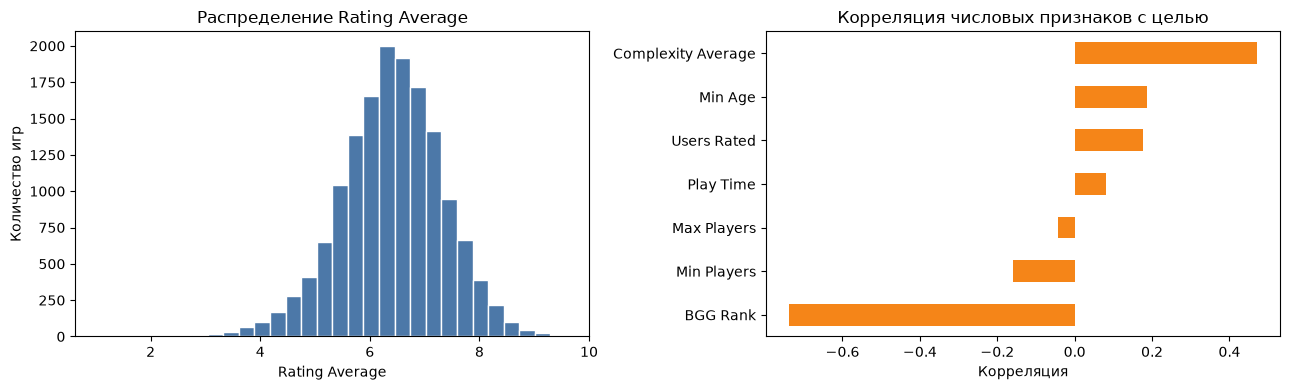

,count,mean,std,min,25%,50%,75%,max
Rating Average,15257.0,6.399775,0.936488,1.05,5.82,6.43,7.02,9.58


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(train[TARGET], bins=30, color='#4C78A8', edgecolor='white')
axes[0].set(title='Распределение Rating Average', xlabel=TARGET, ylabel='Количество игр')

numeric_corr = train.select_dtypes(include=np.number).corr(numeric_only=True)[TARGET].drop(TARGET)
numeric_corr.sort_values().plot.barh(ax=axes[1], color='#F58518')
axes[1].set(title='Корреляция числовых признаков с целью', xlabel='Корреляция')
plt.tight_layout()
plt.show()

display(train[TARGET].describe().to_frame().T)

In [31]:
class BoardGameFeatureEngineer:
    def __init__(self, max_mechanics=120, max_domains=30):
        self.limits = {'Mechanics': max_mechanics, 'Domains': max_domains}

    @staticmethod
    def _encode(series):
        return (series.fillna('').astype(str).str.replace(r'\s*,\s*', ',', regex=True).str.get_dummies(sep=','))

    def fit(self, df):
        text_columns = ['Name', 'Mechanics', 'Domains']

        self.numeric_columns = [column for column in df.columns if column not in text_columns]

        numeric = df[self.numeric_columns].apply(pd.to_numeric, errors='coerce')

        self.medians = numeric.median().to_dict()

        self.categories = {}

        for column, limit in self.limits.items():
            encoded = self._encode(df[column])

            self.categories[column] = (encoded.sum().nlargest(limit).index.tolist())

        return self

    def transform(self, df):
        result = df[self.numeric_columns].apply(pd.to_numeric, errors='coerce').fillna(self.medians).copy()

        result['Name__length'] = (df['Name'].fillna('').str.len())

        result['Players__range'] = (result['Max Players'] - result['Min Players'])

        for column in ['Users Rated', 'Owned Users', 'BGG Rank', 'Play Time',]:
            result[f'log1p__{column}'] = np.log1p(result[column].clip(lower=0))

        for column, categories in self.categories.items():
            encoded = (self._encode(df[column]).reindex(columns=categories, fill_value=0))

            encoded.columns = [f'{column}__{category}' for category in categories]

            result = pd.concat([result, encoded], axis=1)

        return result.astype(float)

    def fit_transform(self, df):
        return self.fit(df).transform(df)

In [32]:
X = train.drop(columns=[TARGET])
y = train[TARGET].astype(float)

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=42
)

feature_engineer = BoardGameFeatureEngineer()
X_train_fe = feature_engineer.fit_transform(X_train)
X_valid_fe = feature_engineer.transform(X_valid)

print('Исходное число признаков:', X.shape[1])
print('После обработки:', X_train_fe.shape[1])
print('Train:', X_train_fe.shape, 'Validation:', X_valid_fe.shape)

Исходное число признаков: 13
После обработки: 144
Train: (12205, 144) Validation: (3052, 144)


In [33]:
hist_model = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=350,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=1.0,
    random_state=42,
)

hist_model.fit(X_train_fe, y_train)


pred_hist = hist_model.predict(X_valid_fe)


validation_predictions = {
    'HistGradientBoosting': pred_hist,

}

scores = pd.DataFrame(
    {'MSE': {name: mean_squared_error(y_valid, pred) for name, pred in validation_predictions.items()}}
).sort_values('MSE')

display(scores)

,MSE
HistGradientBoosting,0.044531


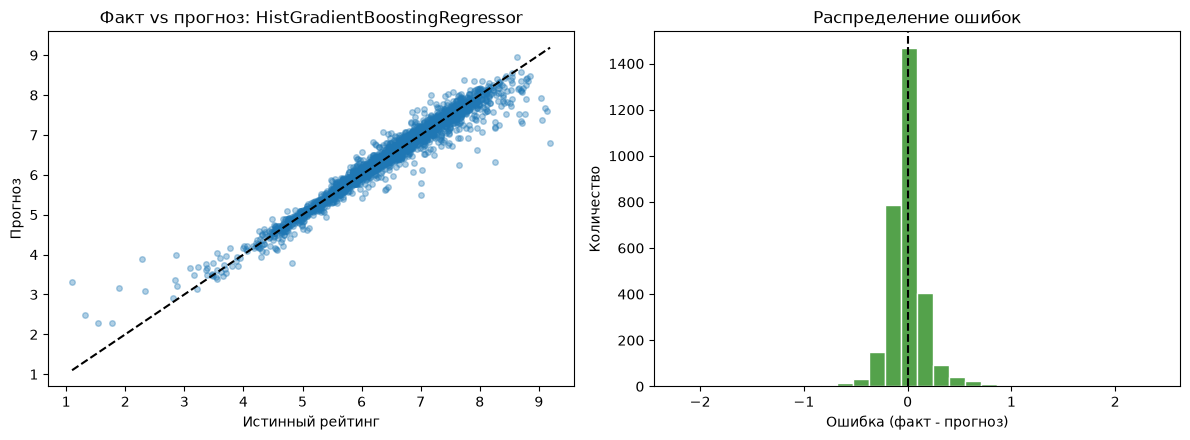

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_valid, pred_hist, alpha=0.35, s=16)
low = min(y_valid.min(), pred_hist.min())
high = max(y_valid.max(), pred_hist.max())
axes[0].plot([low, high], [low, high], '--', color='black')
axes[0].set(xlabel='Истинный рейтинг', ylabel='Прогноз', title=f'Факт vs прогноз: HistGradientBoostingRegressor')

residuals = y_valid.to_numpy() - pred_hist
axes[1].hist(residuals, bins=30, color='#54A24B', edgecolor='white')
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set(xlabel='Ошибка (факт - прогноз)', ylabel='Количество', title='Распределение ошибок')
plt.tight_layout()
plt.show()

In [35]:
final_feature_engineer = BoardGameFeatureEngineer()
X_full_fe = final_feature_engineer.fit_transform(X)
X_test_fe = final_feature_engineer.transform(test)

final_hist = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=350,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=1.0,
    random_state=42,
)


final_hist.fit(X_full_fe, y)


test_pred_hist = final_hist.predict(X_test_fe)



test_predictions = np.clip(test_pred_hist, 0, 10)

print(pd.Series(test_predictions).describe())

count    5086.000000
mean        6.412268
std         0.906281
min         2.254276
25%         5.827106
50%         6.446502
75%         7.045663
max         8.770231
dtype: float64


In [36]:
submission = sample_submission.copy()

submission[TARGET] = test_predictions
submission.to_csv('submission.csv', index=False)

print('Файл сохранён: submission.csv')
print('Размер:', submission.shape)

display(submission.head())


Файл сохранён: submission.csv
Размер: (5086, 2)


,ID,Rating Average
0,0,8.056052
1,1,7.916421
2,2,8.150816
3,3,8.228534
4,4,8.016452
